# Descriptive Invoice Analytics
**Mahmoud Abusahyoun | Data Analytics coursework, HTU**

Rerun using the supplied workbook (532,057 rows). `data/invoices_model_data.csv.gz` retains all rows and the eight columns needed by the analysis; buyer and invoice identifiers are excluded from this analytical view. The complete original workbook can be restored with `python restore_workbook.py`.

All statistics use the complete dataset. Only the scatter plot uses a seeded 30,000-row display sample. Pie labels follow the order of their counts; the final bar chart shows group means rather than overlapping individual invoices. Monetary units are left unspecified because the workbook does not establish a currency.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)
df = pd.read_csv('data/invoices_model_data.csv.gz', float_precision='round_trip')
assert len(df) == 532057
df.head()


,issue_date,collection_type,invoice_sub_type,invoice_category,invoice_discount_amount,invoice_tax_amount,days_overdue,expected_payment_amount
0,1708014393,CREDIT,EXPORT,GENERAL_SALES,0.0,106.23,0,649.84
1,1749262653,CASH,LOCAL,INCOME,0.0,135.67,12,1437.72
2,1642622798,CASH,LOCAL,INCOME,0.0,96.66,12,1216.49
3,1706758339,CREDIT,EXPORT,SPECIAL_SALES,0.0,81.02,0,1817.24
4,1694894569,CREDIT,AREA_OF_DEVELOPMENT,INCOME,0.0,120.53,0,1244.63


In [2]:
df = df.drop(columns=['issue_date'])
assert not df.isna().any().any()
df.describe()

,invoice_discount_amount,invoice_tax_amount,days_overdue,expected_payment_amount
count,532057.000000,532057.000000,532057.000000,532057.000000
mean,109.600338,111.087331,6.792669,1620.316440
std,477.190197,275.696583,15.641736,2928.275601
min,0.000000,0.000000,0.000000,23.310000
25%,0.000000,13.850000,0.000000,634.850000
50%,0.000000,54.120000,3.000000,1178.540000
75%,58.260000,137.270000,10.000000,2019.990000
max,46689.450000,15999.990000,510.000000,109175.910000


In [3]:
# after dropping unnecessary columns i will check the statistical summary of the dataframe
# even though its a simple line of code, it gives me a lot of information about the data 
df.describe()
# this cell allow me to get measueres like the measures of central tendency and measures of dispersion

,invoice_discount_amount,invoice_tax_amount,days_overdue,expected_payment_amount
count,532057.000000,532057.000000,532057.000000,532057.000000
mean,109.600338,111.087331,6.792669,1620.316440
std,477.190197,275.696583,15.641736,2928.275601
min,0.000000,0.000000,0.000000,23.310000
25%,0.000000,13.850000,0.000000,634.850000
50%,0.000000,54.120000,3.000000,1178.540000
75%,58.260000,137.270000,10.000000,2019.990000
max,46689.450000,15999.990000,510.000000,109175.910000


Measures of frequency

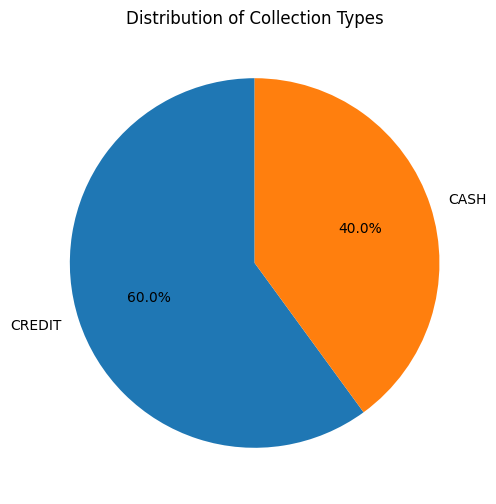

In [4]:
counts = df['collection_type'].value_counts()
plt.figure(figsize=(9, 6))
plt.pie(counts.values, labels=counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Distribution of Collection Types')
plt.show()

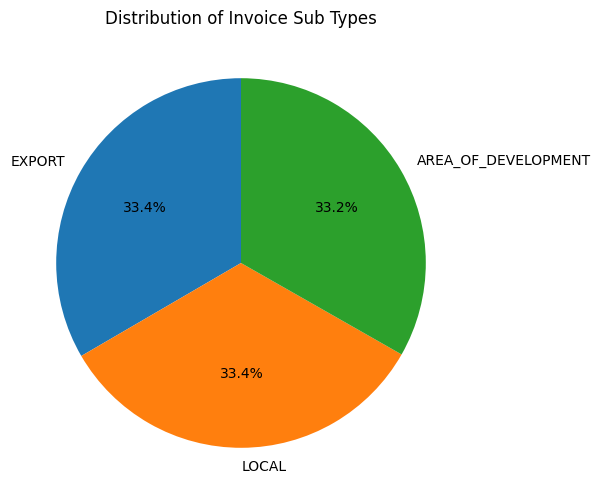

In [5]:
counts = df['invoice_sub_type'].value_counts()
plt.figure(figsize=(9, 6))
plt.pie(counts.values, labels=counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Distribution of Invoice Sub Types')
plt.show()

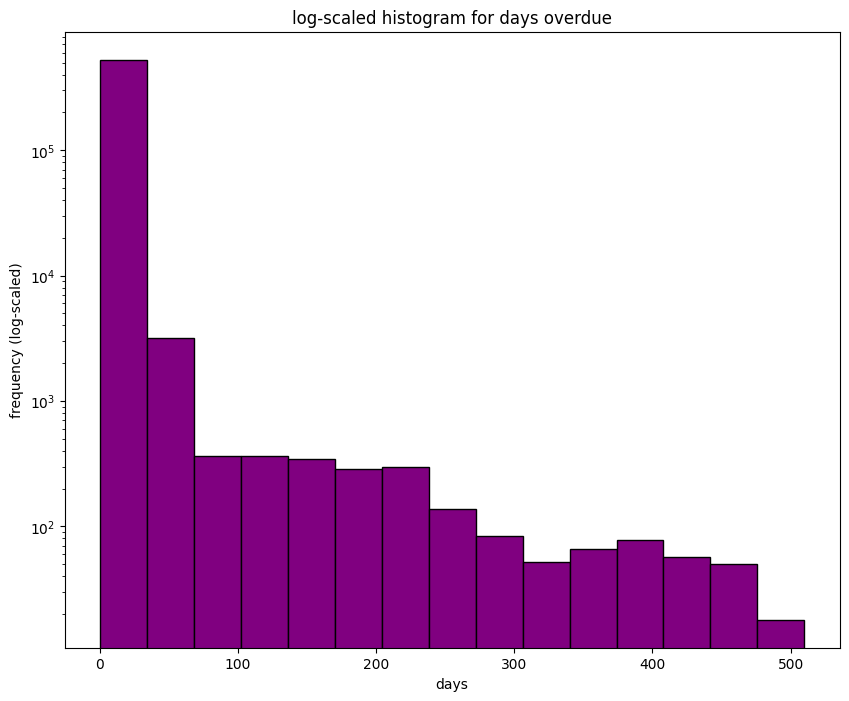

In [6]:
plt.figure(figsize = (10, 8))
plt.hist(df['days_overdue'], bins = 15, color= 'purple', edgecolor = 'black', log = True)
plt.title("log-scaled histogram for days overdue")
plt.xlabel("days")
plt.ylabel("frequency (log-scaled)")
plt.show()


The following charts compare group means for expected payments, taxes and discounts. Interpret the relative sizes from the rerun figures; these summaries describe associations rather than causes.

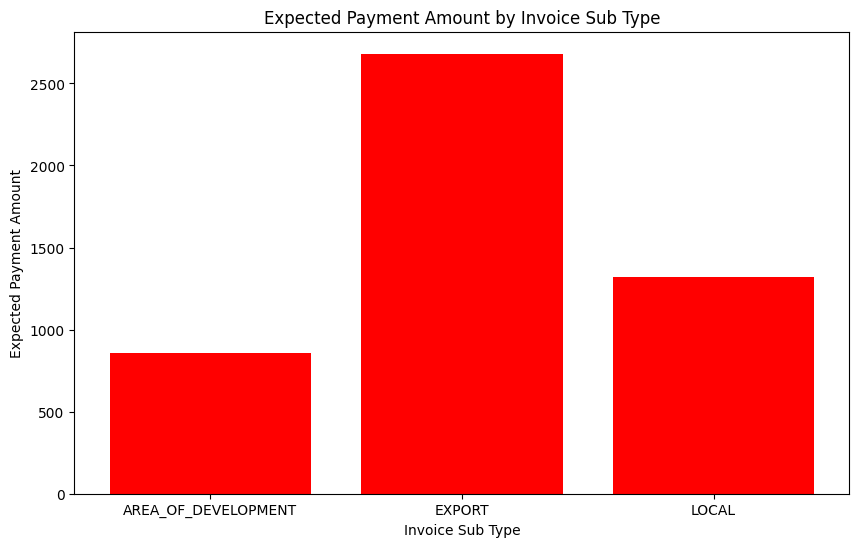

In [7]:
test2 = df.groupby('invoice_sub_type')['expected_payment_amount'].mean()
plt.figure(figsize=(10,6))
plt.bar(test2.index, test2.values, color= 'red')
plt.title("Expected Payment Amount by Invoice Sub Type")
plt.xlabel("Invoice Sub Type")
plt.ylabel("Expected Payment Amount")
plt.show() 

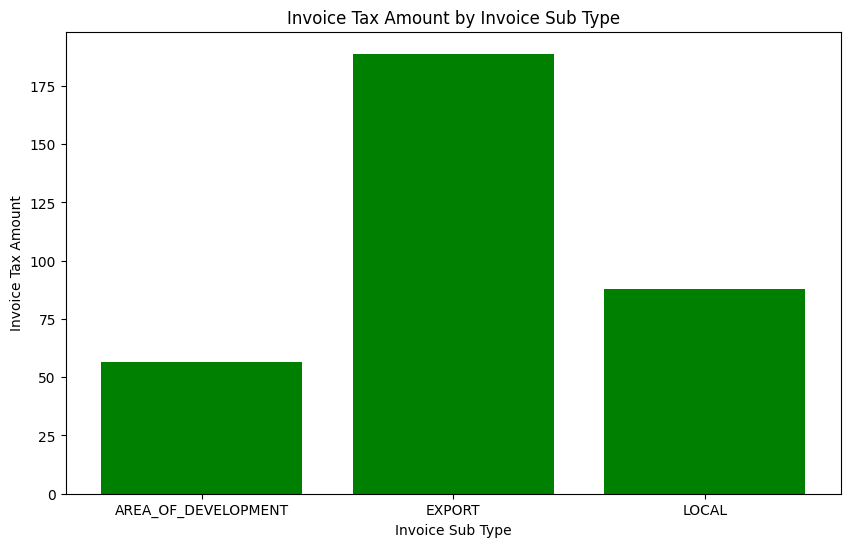

In [8]:
aggregated = df.groupby('invoice_sub_type')['invoice_tax_amount'].mean()

plt.figure(figsize=(10,6))
plt.bar(aggregated.index, aggregated.values, color='green')
plt.title("Invoice Tax Amount by Invoice Sub Type")
plt.xlabel("Invoice Sub Type")
plt.ylabel("Invoice Tax Amount")
plt.show()

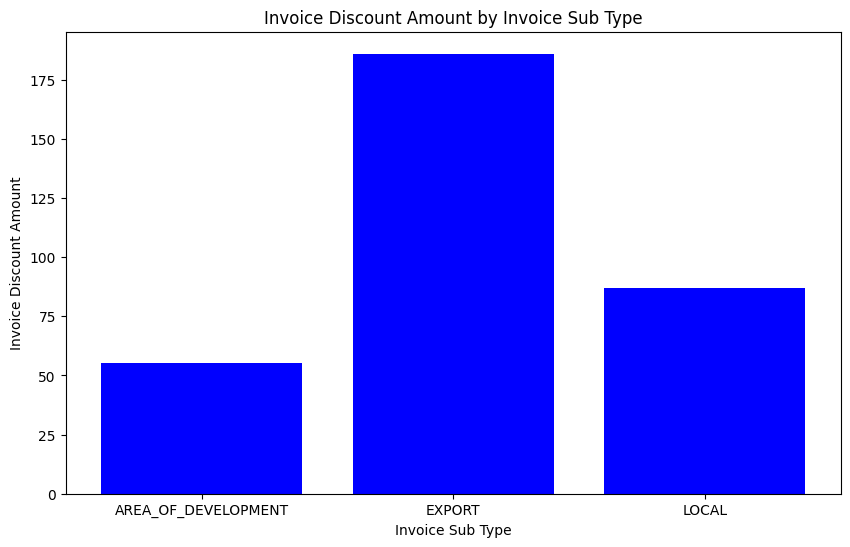

In [9]:
aggregated = df.groupby('invoice_sub_type')['invoice_discount_amount'].mean()
plt.figure(figsize=(10,6))
plt.bar(aggregated.index, aggregated.values, color='blue')
plt.title("Invoice Discount Amount by Invoice Sub Type")
plt.xlabel("Invoice Sub Type")
plt.ylabel("Invoice Discount Amount")
plt.show()

Measurs of central tendency

In [10]:
print('Days overdue mean:', df.days_overdue.mean())
print('Days overdue median:', df.days_overdue.median())
print('Days overdue mode:', df.days_overdue.mode().iloc[0])
print('Days overdue skewness:', df.days_overdue.skew())
# A mean above the median and positive skewness indicate a right-skewed distribution.

Days overdue mean: 6.792668830595218
Days overdue median: 3.0
Days overdue mode: 0
Days overdue skewness: 14.748767402031968


In [11]:
# discount amount mean, mode and median 
print(f"invoice discount amount mean is : {df['invoice_discount_amount'].mean()}")
print(f"invoice discount amount median is : {df['invoice_discount_amount'].median()}")
print(f"invoice discount amount mode is : {df['invoice_discount_amount'].mode()[0]}")

invoice discount amount mean is : 109.60033829082224
invoice discount amount median is : 0.0
invoice discount amount mode is : 0.0


In [12]:
#exploring expected payment amount column
print(f"expected payment amount mean is : {df['expected_payment_amount'].mean()}")
print(f"expected payment amount median is : {df['expected_payment_amount'].median()}")
print(f"expected payment amount mode is : {df['expected_payment_amount'].mode()[0]}")

expected payment amount mean is : 1620.3164399678983
expected payment amount median is : 1178.54
expected payment amount mode is : 378.38


Measures of position

In [13]:
from scipy import stats

numeric_cols = ['days_overdue', 'expected_payment_amount', 'invoice_tax_amount', 'invoice_discount_amount']

for i in numeric_cols:
    z_scores = stats.zscore(df[i])
    z_scores_count = np.sum(np.abs(z_scores) > 3)
    print(f"Number of outliers in {i} (|z| > 3): {z_scores_count}")
    
    z_scores_range = (z_scores.min(), z_scores.max())
    print(f"Z-scores range for {i}: \n {z_scores_range}\n")
    

# calculating the z-score allowed me to identify the number of outliers in all of the numerical columns


Number of outliers in days_overdue (|z| > 3): 2344
Z-scores range for days_overdue: 
 (np.float64(-0.4342660625741475), np.float64(32.17084062469064))

Number of outliers in expected_payment_amount (|z| > 3): 2408
Z-scores range for expected_payment_amount: 
 (np.float64(-0.5453748753740327), np.float64(36.73004501770307))

Number of outliers in invoice_tax_amount (|z| > 3): 1601
Z-scores range for invoice_tax_amount: 
 (np.float64(-0.40293366926188845), np.float64(57.63189899540853))

Number of outliers in invoice_discount_amount (|z| > 3): 4015
Z-scores range for invoice_discount_amount: 
 (np.float64(-0.22967873613818707), np.float64(97.61284651713517))



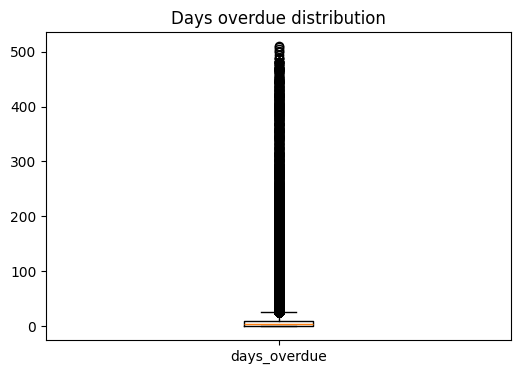

In [14]:
plt.figure(figsize=(6,4))
plt.boxplot(df['days_overdue'], tick_labels=['days_overdue'])
plt.title('Days overdue distribution')
plt.show()

In [15]:
#IQR of days overdue 
Q1 = df['days_overdue'].quantile(0.25)
Q3 = df['days_overdue'].quantile(0.75)
IQR = Q3 - Q1
print(f"the interquartile range (IQR) of days overdue is : {IQR}")

the interquartile range (IQR) of days overdue is : 10.0


Measures of dispersion

In [16]:
#calculate IQR for days overdue 
Q1 = df['days_overdue'].quantile(0.25)
Q3 = df['days_overdue'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df[(df['days_overdue'] < lower_bound) | (df['days_overdue'] > upper_bound)]
print(f"Number of outliers in days_overdue using IQR method: {outliers.shape[0]}")

# The IQR method also helped me to identify the number of outliers in the days overdue column

Number of outliers in days_overdue using IQR method: 16681


In [17]:
#range of days overdue
days_overdue_range = df['days_overdue'].max() - df['days_overdue'].min()
print(f"Range of days overdue: {days_overdue_range}")
                                                   

Range of days overdue: 510


In [18]:
print(f"the Range of invoice_discount_amount is : {df['invoice_discount_amount'].max() - df['invoice_discount_amount'].min()}")

print(f"the range of expected_payment_amount is : {df['expected_payment_amount'].max() - df['expected_payment_amount'].min()}")

the Range of invoice_discount_amount is : 46689.45
the range of expected_payment_amount is : 109152.6


In [19]:
#IQR of days overdue 
Q1 = df['days_overdue'].quantile(0.25)
Q3 = df['days_overdue'].quantile(0.75)
IQR = Q3 - Q1
print(f"the interquartile range (IQR) of days overdue is : {IQR}")

#coefficient of variation (CV) for days overdue
cv_days_overdue = (df['days_overdue'].std() / df['days_overdue'].mean()) * 100
print(f"the coefficient of variation (CV) for days overdue is : {cv_days_overdue}%")


the interquartile range (IQR) of days overdue is : 10.0
the coefficient of variation (CV) for days overdue is : 230.27379432384706%


Visualizations

<Figure size 1200x800 with 0 Axes>

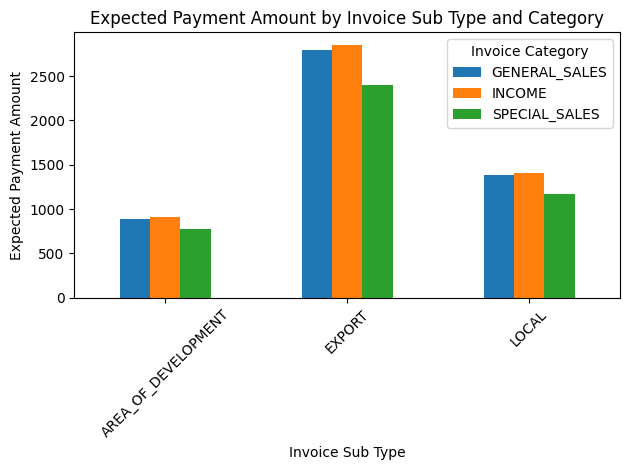

In [20]:
multi_bar = df.groupby(['invoice_sub_type', 'invoice_category'])['expected_payment_amount'].mean().unstack()
plt.figure(figsize=(12,8))
multi_bar.plot(kind='bar')
plt.title("Expected Payment Amount by Invoice Sub Type and Category")
plt.xlabel("Invoice Sub Type")
plt.ylabel("Expected Payment Amount")
plt.xticks(rotation=45)
plt.legend(title='Invoice Category')
plt.tight_layout()
plt.show()
# this grouped bar chart allows me to compare the expected payment amounts across different invoice sub types and categories
# it helps to identify which combinations of sub types and categories have higher or lower expected payments

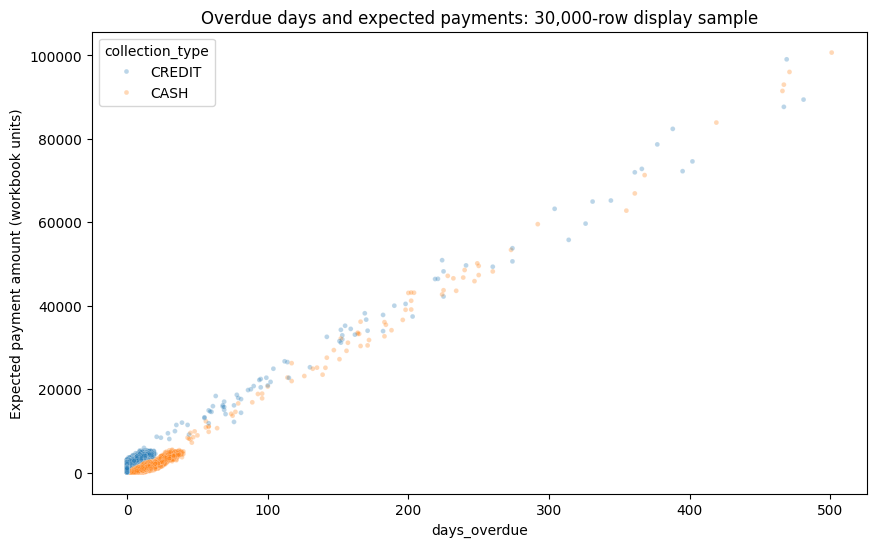

In [21]:
plot_data = df.sample(n=min(30000, len(df)), random_state=42)
plt.figure(figsize=(10,6))
sns.scatterplot(data=plot_data, x='days_overdue', y='expected_payment_amount', hue='collection_type', alpha=.3, s=12)
plt.title('Overdue days and expected payments: 30,000-row display sample')
plt.ylabel('Expected payment amount (workbook units)')
plt.show()

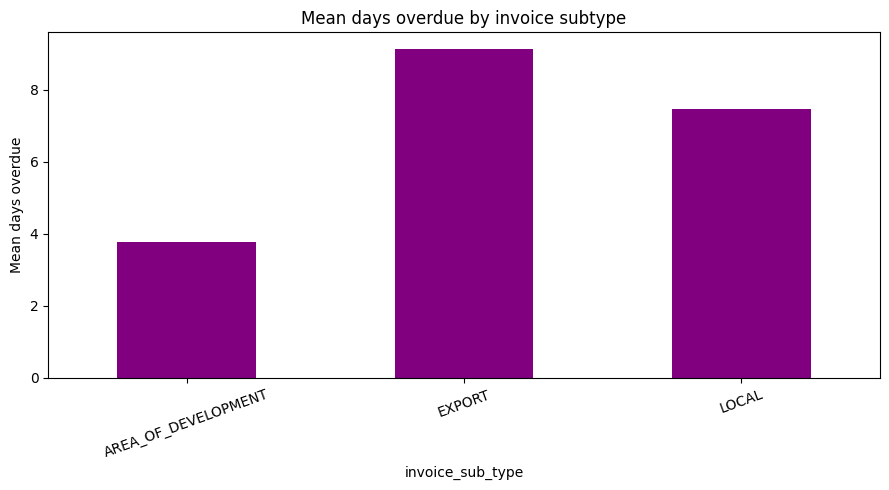

In [22]:
group_means = df.groupby('invoice_sub_type')['days_overdue'].mean()
group_means.plot.bar(color='purple', figsize=(9,5))
plt.title('Mean days overdue by invoice subtype')
plt.ylabel('Mean days overdue')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [23]:
df.describe().to_csv(RESULTS / 'descriptive_statistics.csv')
for col in ['collection_type', 'invoice_sub_type', 'invoice_category']:
    df[col].value_counts().rename_axis(col).to_csv(RESULTS / (col + '_counts.csv'))
print('Full-dataset statistics saved for', len(df), 'rows.')

Full-dataset statistics saved for 532057 rows.
